# 09 · Robustness (Prompt 15)

Does the headline survive different baselines, model families, the economic control, boundary changes and Phoenix's weather
drift? How do our estimates compare with what utilities report? Built by `python -m glg.models.robustness` (refits) and
`python -m glg.models.supply_gap` (regional capacity factors). (CLAUDE.md names this notebook 05_robustness; 05 was taken.)

In [1]:
import polars as pl, numpy as np, matplotlib.pyplot as plt
from glg.config import FIGURES_DIR, REFERENCE_DIR
from glg.models import robustness as rb, growth as g, supply_gap as sg
pl.Config(tbl_rows=40, tbl_cols=16, tbl_width_chars=230)
grid = pl.read_csv(rb.GRID_PATH); med = pl.read_csv(rb.MEDIANS_PATH); rank = pl.read_csv(g.RANKING_PATH)

## Robustness grid: weather-adjusted growth since 2022 (%), by specification

In [2]:
grid.filter(pl.col('headline')).sort('gam_2016_19', descending=True).with_columns(pl.col(pl.Float64).round(1))

ba,gam_2016_19,gbm,ddr,gam_2017_19,gam_start_yr,gam_emp,gam_phx_warm,min_pct,max_pct,headline,role
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,str
"""DOM""",23.6,23.9,23.7,23.6,23.8,17.7,23.6,17.7,23.9,true,"""focus"""
"""ERCO""",19.5,19.3,20.1,19.3,19.2,10.9,19.5,10.9,20.1,true,"""focus"""
"""AZPS""",16.6,16.9,15.0,16.5,16.3,20.8,15.8,15.0,20.8,true,"""focus"""
"""AZPS+SRP""",13.7,13.9,12.3,13.7,13.5,14.2,13.0,12.3,14.2,true,"""focus"""
"""BPAT""",13.2,13.1,12.8,13.0,12.8,12.2,13.2,12.2,13.2,true,"""focus"""
"""SWPP""",10.9,10.9,11.2,10.9,10.8,4.6,10.9,4.6,11.2,true,"""comparison"""
"""GCPD""",10.6,9.1,10.3,9.7,9.9,4.0,10.6,4.0,10.6,true,"""focus"""
"""SRP""",9.5,9.3,9.6,9.4,9.0,6.7,8.6,6.7,9.6,true,"""focus"""
"""NEVP""",8.8,8.9,8.7,8.8,8.1,5.2,8.8,5.2,8.9,true,"""focus"""


## The core comparison under every specification (medians, %)

In [3]:
med.with_columns(pl.col(pl.Float64).round(2))

grouping,spec,excl_boundary_bas,dc_median_pct,comp_median_pct,gap_pts,ratio
str,str,bool,f64,f64,f64,f64
"""dc6_vs_d10""","""gam_2016_19""",false,13.44,3.31,10.13,4.07
"""dc6_vs_d10""","""gbm""",false,13.52,3.55,9.97,3.81
"""dc6_vs_d10""","""ddr""",false,12.54,3.5,9.04,3.58
"""dc6_vs_d10""","""gam_2017_19""",false,13.37,3.27,10.09,4.08
"""dc6_vs_d10""","""gam_start_yr""",false,13.16,3.4,9.77,3.88
"""dc6_vs_d10""","""gam_emp""",false,11.55,2.96,8.59,3.91
"""dc6_vs_d10""","""gam_phx_warm""",false,13.08,3.31,9.78,3.96
"""dc6_vs_d10""","""gam_2016_19""",true,13.19,2.94,10.25,4.49
"""dc6_vs_d10""","""gbm""",true,13.15,3.04,10.1,4.32


## Specification curve / forest plot

Each row: the headline estimate (blue, with its 95% interval) and every alternative specification (grey marks); the grey bar spans
the lowest to highest. Beyond-trend (D11) is shown as an open diamond.

2026-11-08 17:51:01,319 INFO robustness_forest (light): robustness_forest.png, robustness_forest.svg


2026-11-08 17:51:01,570 INFO robustness_forest (dark): robustness_forest_dark.png, robustness_forest_dark.svg


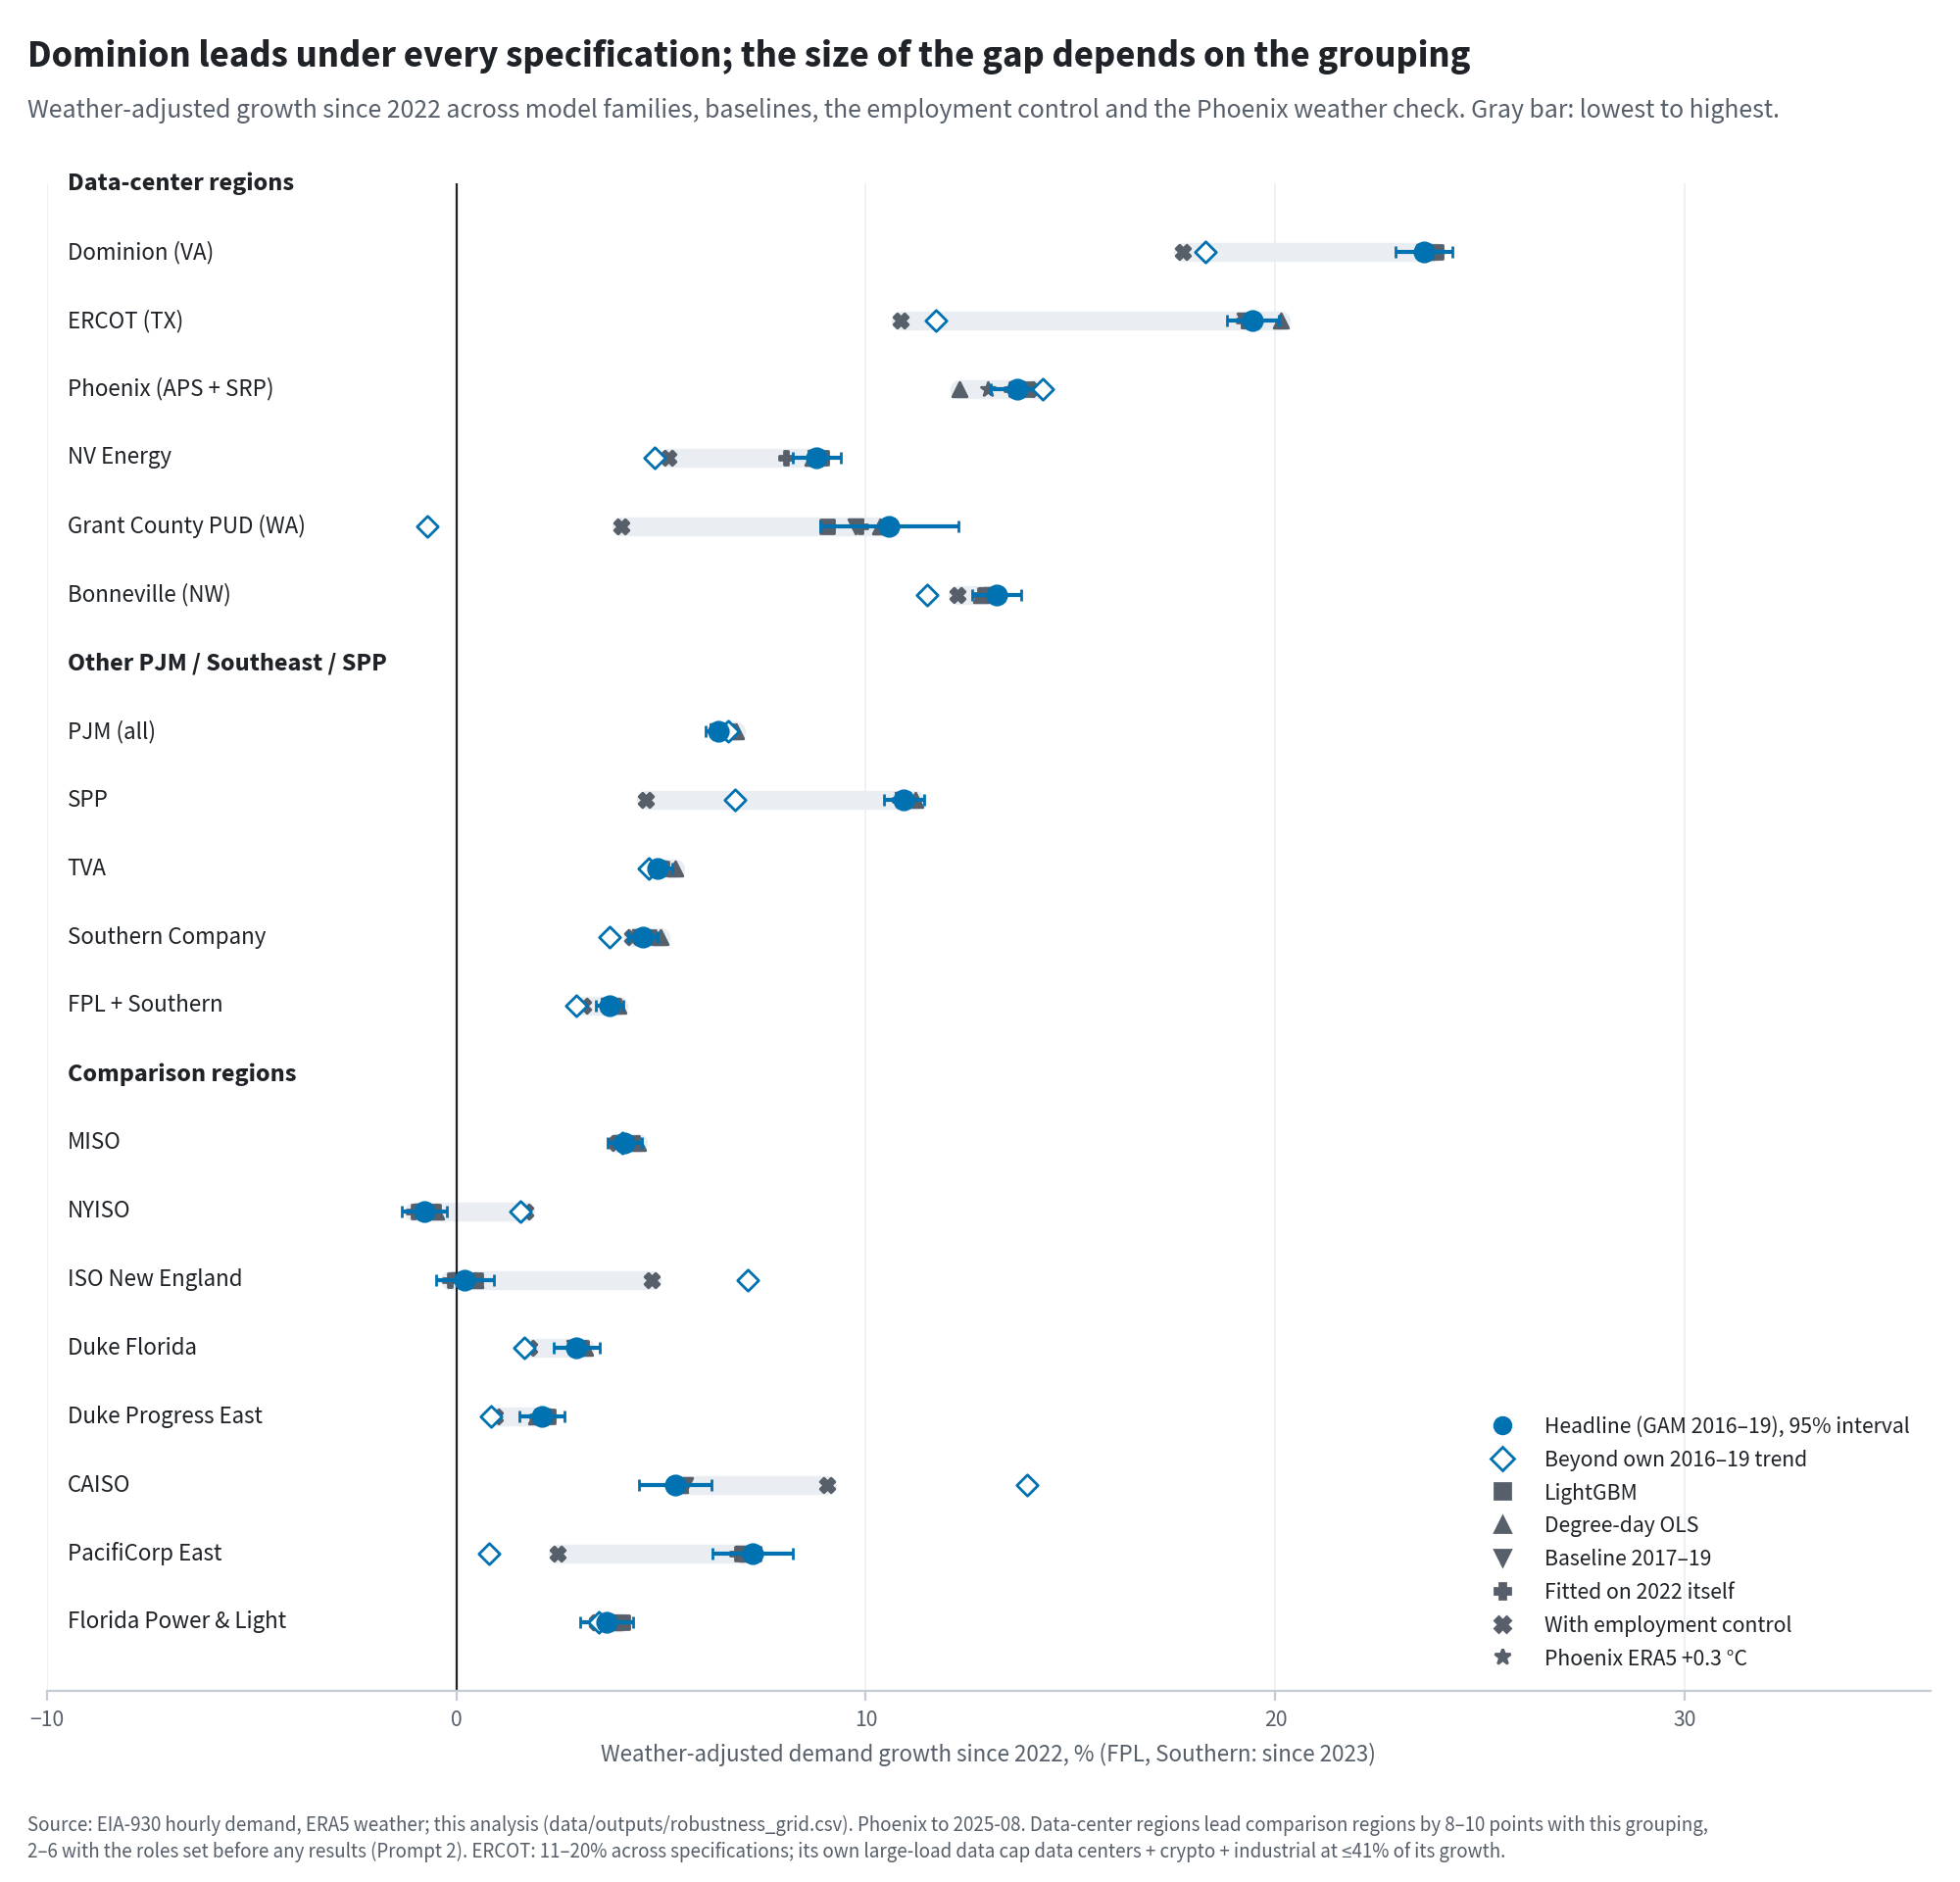

In [4]:
# Final themed figure (Prompt 16): light + dark, PNG + SVG in report/figures/
from IPython.display import Image
from glg.viz import figures as F
F.main(['robustness_forest'])
Image(filename=str(F.FIGURES_DIR / 'robustness_forest.png'), width=900)

## Supply gap with regional capacity factors (state solar and wind factors from EIA generation ÷ 860M capacity)

In [5]:
a = pl.read_csv(sg.SINCE_PATH).select('series', 'demand_twh_added', 'new_supply_twh', 'gap_pct')
b = pl.read_csv(sg.SINCE_REGIONAL_PATH).select('series', pl.col('new_supply_twh').alias('supply_regional_cf'), pl.col('gap_pct').alias('gap_regional_cf'))
a.join(b, on='series').filter(pl.col('series').is_in(rb.DC + rb.COMP + ['PJM'])).with_columns(pl.col(pl.Float64).round(1))

series,demand_twh_added,new_supply_twh,gap_pct,supply_regional_cf,gap_regional_cf
str,f64,f64,f64,f64,f64
"""ERCO""",82.8,65.1,-4.1,71.1,-2.7
"""PJM""",52.6,17.6,-4.3,13.5,-4.8
"""DOM""",28.1,1.4,-23.3,0.4,-24.1
"""MISO""",26.9,25.6,-0.2,21.3,-0.9
"""CISO""",12.0,21.6,4.3,24.5,5.6
"""AZPS+SRP""",8.9,5.2,-5.7,5.6,-5.1
"""BPAT""",7.3,1.0,-10.9,0.8,-11.1
"""FPL""",5.4,8.3,2.0,7.9,1.8
"""PACE""",3.6,6.5,5.6,7.2,7.0


In [6]:
pl.read_csv(sg.REGIONAL_CF_PATH).filter(pl.col('state').is_in(['VA', 'TX', 'AZ', 'NV', 'OR', 'WA', 'GA', 'CA'])).with_columns(pl.col(pl.Float64).round(3))

state,cf_group,cf_state,mw_latest
str,str,f64,f64
"""AZ""","""solar_pv""",0.282,2846.433
"""CA""","""solar_pv""",0.265,17302.517
"""GA""","""solar_pv""",0.237,3780.067
"""NV""","""solar_pv""",0.305,3502.2
"""OR""","""solar_pv""",0.229,930.033
"""TX""","""solar_pv""",0.265,12344.967
"""VA""","""solar_pv""",0.204,3070.975
"""WA""","""solar_pv""",0.248,188.3
"""AZ""","""wind""",0.27,776.1


## Our estimates vs utility disclosures (measured load only)

In [7]:
dc = pl.read_csv(REFERENCE_DIR / 'dominion_dc_demand.csv')
ann = pl.read_csv(g.ANNUAL_PATH)
dom = ann.filter(pl.col('ba') == 'DOM').select('year', 'resid_mw').join(dc.select('year', 'coincident_mw', 'billing_mw'), on='year', how='inner')
dom.with_columns(pl.col(pl.Float64).round(0))

year,resid_mw,coincident_mw,billing_mw
i64,f64,i64,i64
2018,-99.0,null,1113
2019,30.0,null,1421
2020,291.0,1697,1808
2021,987.0,2152,2302
2022,1609.0,2626,2767
2023,2188.0,3040,3183
2024,2864.0,3410,3636
2025,3911.0,3999,4237
2026,4927.0,4559,4838


In [8]:
gd = {r['ba']: r for r in grid.iter_rows(named=True)}; rk = {r['ba']: r for r in rank.iter_rows(named=True)}
def d(df, col, y0, y1):
    v = dict(zip(df['year'], df[col]))
    return v[y1] - v[y0]
rows = [
    ('DOM', 'Dominion metered data-center coincident demand, 2022→2025', d(dom, 'coincident_mw', 2022, 2025), d(dom, 'resid_mw', 2022, 2025)),
    ('DOM', 'Dominion data-center billing demand, 2019→2025', d(dom, 'billing_mw', 2019, 2025), d(dom, 'resid_mw', 2019, 2025)),
    ('ERCO', 'ERCOT: all approved large loads, observed peak (Mar 2026, level)', 3883, rk['ERCO']['mw_added']),
    ('GCPD', 'Grant PUD data-center load 2025 (aMW, level)', 280, gd and float(ann.filter((pl.col('ba') == 'GCPD') & (pl.col('year') == 2025))['resid_mw'][0])),
    ('AZPS+SRP', 'APS: data-center share of 2026 peak growth (~MW)', 200, rk['AZPS+SRP']['mw_added']),
]
cmp = pl.DataFrame(rows, schema=['series', 'utility_measure', 'utility_mw', 'our_mw'], orient='row').with_columns(
    (pl.col('utility_mw') / pl.col('our_mw')).round(2).alias('utility_over_ours'))
cmp

series,utility_measure,utility_mw,our_mw,utility_over_ours
str,str,i64,f64,f64
"""DOM""","""Dominion metered data-center c…",1373,2301.2371,0.6
"""DOM""","""Dominion data-center billing d…",2816,3880.1094,0.73
"""ERCO""","""ERCOT: all approved large load…",3883,9440.354,0.41
"""GCPD""","""Grant PUD data-center load 202…",280,190.303,1.47
"""AZPS+SRP""","""APS: data-center share of 2026…",200,1012.775,0.2
